# Miau-net — Exploração de Dados e Machine Learning

## Análise de dados e classificação de desfechos de adoção de gatos

### Objetivo

Explorar os dados históricos de entradas e desfechos de gatos em um abrigo animal, identificar inconsistências, preparar as variáveis e investigar padrões associados ao tempo de permanência e à adoção.

Inicialmente, foi explorada a possibilidade de estimar o tempo de permanência por meio de modelos de regressão. Posteriormente, o trabalho avançou para a classificação dos registros entre adoção e outros desfechos conhecidos, utilizando Regressão Logística.

A etapa de classificação constitui a abordagem utilizada na aplicação final do projeto Miau-net.

### Etapas do notebook

1. Exploração e compreensão da base de dados.
2. Identificação de valores ausentes e inconsistências.
3. Engenharia de atributos e criação da variável de idade na entrada.
4. Análise exploratória do tempo de permanência.
5. Experimentos iniciais de regressão.
6. Definição da variável-alvo de classificação.
7. Preparação das variáveis preditoras.
8. Treinamento e comparação dos classificadores.
9. Avaliação do modelo final.
10. Salvamento do modelo, do pré-processador e dos resultados.

In [102]:
# ==========================================
# Importação das Bibliotecas
# ==========================================

# Manipulação e análise de dados
import pandas as pd
import numpy as np

# Visualização dos dados
import matplotlib.pyplot as plt
import seaborn as sns


# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap





In [3]:
df = pd.read_csv("../dados/original/animal-shelter-intakes-and-outcomes.csv")

In [4]:
# Primeira visualização da base

df.head()

,Kennel ID,Animal ID,Animal Name,Animal Type,Primary Color,Secondary Color,Sex,DOB,Intake Date,Intake Condition,...,longitude,intake_is_dead,geopoint,intake_duration,is_current_month,outcome_is_dead,outcome_is_current,outcome_is_other,outcome_is_alive,was_outcome_alive
0,325786,A659977,*HART,RABBIT,WHITE,NaN,Spayed,2020-07-06,2021-07-06,NORMAL,...,-118.086983,Alive on Intake,"33.8095992, -118.086983",16.0,False,False,False,False,True,1
1,324535,A657444,NaN,REPTILE,GREEN,NaN,Male,NaN,2021-05-14,INJURED MODERATE,...,-118.086983,Alive on Intake,"33.8095992, -118.086983",0.0,False,False,False,False,True,1
2,290399,A599451,NaN,WILD,BROWN,NaN,Unknown,NaN,2017-10-30,ILL SEVERE,...,-118.086983,Alive on Intake,"33.8095992, -118.086983",0.0,False,True,False,False,False,0
3,288918,A596830,BEAUTY,DOG,WHITE,NaN,Female,2015-09-09,2017-09-10,NORMAL,...,-118.086983,Alive on Intake,"33.8095992, -118.086983",0.0,False,False,False,False,True,1
4,295840,A609515,NaN,CAT,TORTIE,NaN,Female,2018-03-26,2018-06-10,NORMAL,...,-118.086983,Alive on Intake,"33.8095992, -118.086983",6.0,False,False,False,False,True,1


In [5]:
df. columns


Index(['Kennel ID', 'Animal ID', 'Animal Name', 'Animal Type', 'Primary Color',
       'Secondary Color', 'Sex', 'DOB', 'Intake Date', 'Intake Condition',
       'Intake Type', 'Intake Subtype', 'Reason for Intake', 'Outcome Date',
       'Crossing', 'Jurisdiction', 'Outcome Type', 'Outcome Subtype',
       'latitude', 'longitude', 'intake_is_dead', 'geopoint',
       'intake_duration', 'is_current_month', 'outcome_is_dead',
       'outcome_is_current', 'outcome_is_other', 'outcome_is_alive',
       'was_outcome_alive'],
      dtype='str')

In [6]:
df.shape

(57562, 29)

In [7]:
# Informações gerais da base
df.info()

# Quantidade de valores ausentes por coluna

df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 57562 entries, 0 to 57561
Data columns (total 29 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Kennel ID           57562 non-null  int64  
 1   Animal ID           57562 non-null  str    
 2   Animal Name         34200 non-null  str    
 3   Animal Type         57562 non-null  str    
 4   Primary Color       57562 non-null  str    
 5   Secondary Color     26949 non-null  str    
 6   Sex                 57562 non-null  str    
 7   DOB                 50070 non-null  str    
 8   Intake Date         57562 non-null  str    
 9   Intake Condition    57562 non-null  str    
 10  Intake Type         57562 non-null  str    
 11  Intake Subtype      56722 non-null  str    
 12  Reason for Intake   3613 non-null   str    
 13  Outcome Date        57179 non-null  str    
 14  Crossing            57395 non-null  str    
 15  Jurisdiction        57561 non-null  str    
 16  Outcome Type   

Kennel ID                 0
Animal ID                 0
Animal Name           23362
Animal Type               0
Primary Color             0
Secondary Color       30613
Sex                       0
DOB                    7492
Intake Date               0
Intake Condition          0
Intake Type               0
Intake Subtype          840
Reason for Intake     53949
Outcome Date            383
Crossing                167
Jurisdiction              1
Outcome Type            402
Outcome Subtype        5918
latitude                  0
longitude                 0
intake_is_dead            0
geopoint                  0
intake_duration         383
is_current_month          0
outcome_is_dead           0
outcome_is_current        0
outcome_is_other          0
outcome_is_alive          0
was_outcome_alive         0
dtype: int64

In [8]:
# Verificando registros sem tempo de permanência

df[df["intake_duration"].isnull()][
    ["Animal ID", "Animal Type","Intake Date", "Outcome Date", "intake_duration"]
]

,Animal ID,Animal Type,Intake Date,Outcome Date,intake_duration
71,A767667,DOG,2026-09-24,NaN,NaN
221,A767186,CAT,2026-09-12,NaN,NaN
372,A765504,CAT,2026-08-09,NaN,NaN
412,A767647,CAT,2026-09-24,NaN,NaN
472,A765132,DOG,2026-08-01,NaN,NaN
...,...,...,...,...,...
57008,A760467,CAT,2026-05-13,NaN,NaN
57011,A760468,CAT,2026-05-13,NaN,NaN
57125,A766537,CAT,2026-09-02,NaN,NaN
57391,A764606,DOG,2026-07-23,NaN,NaN


In [9]:
# Quantidade de registros por tipo de animal

df["Animal Type"].value_counts()

Animal Type
CAT           27295
DOG           18145
BIRD           4421
OTHER          2971
WILD           2707
RABBIT         1061
REPTILE         613
GUINEA PIG      325
LIVESTOCK        21
AMPHIBIAN         3
Name: count, dtype: int64

In [10]:
# Filtrando somente os gatos

df_gatos = df[df["Animal Type"]=="CAT"].copy()

In [11]:
df_gatos.shape

(27295, 29)

In [12]:
# Valores ausentes na base de gatos

df_gatos.isnull().sum()


Kennel ID                 0
Animal ID                 0
Animal Name           10511
Animal Type               0
Primary Color             0
Secondary Color       16337
Sex                       0
DOB                    1067
Intake Date               0
Intake Condition          0
Intake Type               0
Intake Subtype          306
Reason for Intake     25974
Outcome Date            237
Crossing                 79
Jurisdiction              0
Outcome Type            245
Outcome Subtype        2617
latitude                  0
longitude                 0
intake_is_dead            0
geopoint                  0
intake_duration         237
is_current_month          0
outcome_is_dead           0
outcome_is_current        0
outcome_is_other          0
outcome_is_alive          0
was_outcome_alive         0
dtype: int64

In [13]:
# Quantidade de categorias por variável categórica
colunas_categoricas = [
    "Sex",
    "Intake Condition",
    "Intake Type",
    "Intake Subtype",
    "Outcome Type"
 ]
for coluna in colunas_categoricas:
    print(f"{coluna}: {df_gatos[coluna].nunique(dropna=False)} categorias")



Sex: 5 categorias
Intake Condition: 17 categorias
Intake Type: 11 categorias
Intake Subtype: 20 categorias
Outcome Type: 19 categorias


In [14]:
# Verificando registros duplicados

df_gatos.duplicated().sum()

np.int64(0)

In [15]:
# Estatísticas do tempo de permanência

df_gatos["intake_duration"].describe()

count    27058.00000
mean        24.08175
std         53.59273
min          0.00000
25%          1.00000
50%          7.00000
75%         28.00000
max       1410.00000
Name: intake_duration, dtype: float64

In [16]:
# Maiores tempos de permanência registrados
df_gatos[
     ["Animal ID", "Animal Name", "Intake Date", "Outcome Date", "intake_duration"]
].sort_values(
    "intake_duration",
    ascending=False 
).head(10)

,Animal ID,Animal Name,Intake Date,Outcome Date,intake_duration
55028,A641344,*ZEN,2020-03-23,2024-02-01,1410.0
45362,A639901,*MCCALLISTER,2020-02-13,2023-11-30,1386.0
15631,A628400,NaN,2019-06-16,2022-07-13,1123.0
22040,A629132,MACY,2019-06-29,2022-07-10,1107.0
32320,A633435,NaN,2019-09-11,2022-09-07,1092.0
5454,A630511,NaN,2019-07-24,2022-07-10,1082.0
5453,A630509,NaN,2019-07-24,2022-07-10,1082.0
44131,A631084,*DONUT,2019-08-01,2022-07-10,1074.0
38515,A633943,NaN,2019-09-20,2022-06-26,1010.0
17719,A634863,NaN,2019-10-10,2022-06-26,990.0


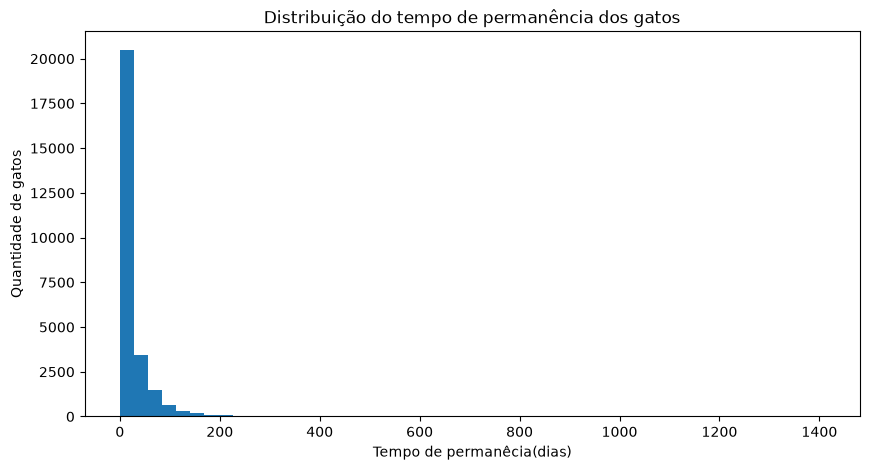

In [ ]:
# ==========================================
# Distribuição do tempo de permanência
# ==========================================

plt.figure(figsize=(10,5))

plt.hist(
    df_gatos["intake_duration"].dropna(),
    bins=50
)

plt.xlabel("Tempo de permanêcia(dias)")
plt.ylabel("Quantidade de gatos")
plt.title("Distribuição do tempo de permanência dos gatos")

plt.show()

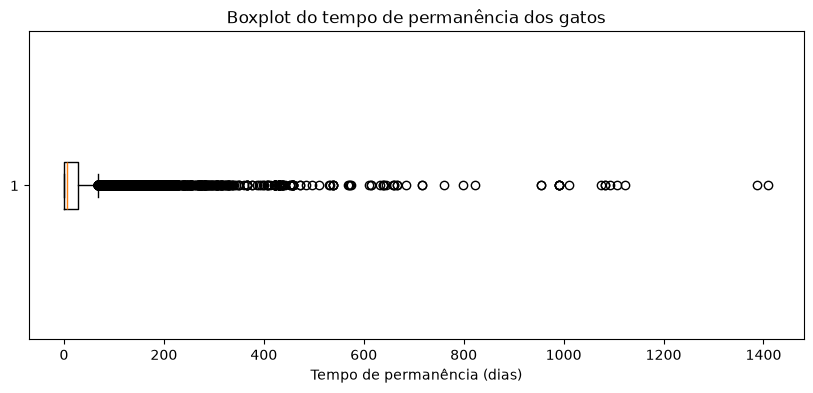

In [ ]:
# ==========================================
# Boxplot do tempo de permanência
# ==========================================

plt.figure(figsize=(10, 4))

plt.boxplot(
    df_gatos["intake_duration"].dropna(),
    orientation="horizontal"
)

plt.xlabel("Tempo de permanência (dias)")
plt.title("Boxplot do tempo de permanência dos gatos")

plt.show()

In [19]:
# Verificando o formato das datas

df_gatos[["DOB", "Intake Date", "Outcome Date"]].head(10)

,DOB,Intake Date,Outcome Date
4,2018-03-26,2018-06-10,2018-06-16
7,2019-09-08,2019-10-08,2019-10-22
12,2015-11-16,2018-11-16,2019-04-30
13,2015-11-16,2018-11-16,2018-11-28
15,2019-06-09,2019-06-23,2019-06-23
16,2019-02-26,2019-03-26,2019-03-27
17,2019-02-26,2019-03-26,2019-03-27
18,2017-08-30,2019-08-30,2020-03-23
25,2017-02-27,2017-03-27,2017-03-27
26,2018-05-04,2018-06-09,2018-07-26


In [20]:
# Verificando possíveis datas inválidas

for coluna in ["DOB", "Intake Date", "Outcome Date"]:
    datas = pd.to_datetime(df_gatos[coluna], errors="coerce")
    
    print(f"{coluna}:")
    print(f"  Datas inválidas: {datas.isna().sum()}")
    print()

DOB:
  Datas inválidas: 1067

Intake Date:
  Datas inválidas: 0

Outcome Date:
  Datas inválidas: 237



In [21]:
# Verificando a ordem cronológica das datas

intake = pd.to_datetime(df_gatos["Intake Date"], errors="coerce")
outcome = pd.to_datetime(df_gatos["Outcome Date"], errors="coerce")
dob = pd.to_datetime(df_gatos["DOB"], errors="coerce")

print("Outcome Date anterior à Intake Date:",
      (outcome < intake).sum())

print("DOB posterior à Intake Date:",
      (dob > intake).sum())

Outcome Date anterior à Intake Date: 0
DOB posterior à Intake Date: 189


In [22]:
# Investigando datas de nascimento posteriores à entrada

df_gatos[
    ["Animal ID", "Animal Name", "DOB", "Intake Date", "Outcome Date"]
][
    pd.to_datetime(df_gatos["DOB"], errors="coerce")
    > pd.to_datetime(df_gatos["Intake Date"], errors="coerce")
].head(10)

,Animal ID,Animal Name,DOB,Intake Date,Outcome Date
187,A695431,*MOMMA FRANCES 1,2023-03-09,2023-03-08,2023-03-24
255,A588789,NaN,2017-04-19,2017-04-11,2017-05-01
551,A767213,NaN,2026-09-13,2026-09-11,NaN
1098,A612916,*FIGGY,2018-05-16,2017-05-23,2017-06-08
1337,A631609,*CUPID,2019-08-09,2019-08-08,2019-12-22
2991,A758441,NaN,2026-03-31,2026-03-29,2026-04-05
2992,A758440,NaN,2026-03-31,2026-03-29,2026-04-05
2995,A758443,NaN,2026-03-31,2026-03-29,2026-04-05
4031,A609076,NaN,2018-06-03,2018-05-27,2018-06-12
4053,A608617,*ALEKEI,2018-05-27,2018-05-23,2018-07-13


In [23]:
# Diferença entre a data de nascimento e a data de entrada

dob = pd.to_datetime(df_gatos["DOB"], errors="coerce")
intake = pd.to_datetime(df_gatos["Intake Date"], errors="coerce")

diferenca_dias = (intake - dob).dt.days

casos_inconsistentes = diferenca_dias < 0

print("Total de casos com DOB posterior à entrada:")
print(casos_inconsistentes.sum())

print("\nDistribuição das diferenças:")

print(
    pd.cut(
        diferenca_dias[casos_inconsistentes],
        bins=[-float("inf"), -365, -30, -7, -1],
        labels=[
            "Mais de 1 ano",
            "31 a 365 dias",
            "8 a 30 dias",
            "1 a 7 dias"
        ]
    ).value_counts().sort_index()
)

Total de casos com DOB posterior à entrada:
189

Distribuição das diferenças:
Mais de 1 ano      2
31 a 365 dias     17
8 a 30 dias       45
1 a 7 dias       125
Name: count, dtype: int64


In [24]:
# Calculando a idade do gato no momento da entrada

dob = pd.to_datetime(df_gatos["DOB"], errors="coerce")
intake = pd.to_datetime(df_gatos["Intake Date"], errors="coerce")

idade_dias = (intake - dob).dt.days
idade_anos = idade_dias / 365.25

print("Quantidade de idades calculadas:")
print(idade_anos.notna().sum())

print("\nEstatísticas da idade:")
print(idade_anos.describe())

Quantidade de idades calculadas:
26228

Estatísticas da idade:
count    26228.000000
mean         1.283957
std          2.479858
min         -9.938398
25%          0.082136
50%          0.167009
75%          1.002053
max         24.000000
dtype: float64


In [ ]:
# ==========================================
# Analisando as idades negativas
# ==========================================

print("Idades negativas:")
print((idade_dias < 0).sum())

print("\nIdades iguais a zero:")
print((idade_dias == 0).sum())

print("\nIdades entre 0 e 30 dias:")
print(((idade_dias > 0) & (idade_dias <= 30)).sum())

print("\nIdades entre 31 e 365 dias:")
print(((idade_dias > 30) & (idade_dias <= 365)).sum())

Idades negativas:
189

Idades iguais a zero:
395

Idades entre 0 e 30 dias:
6942

Idades entre 31 e 365 dias:
11920


In [26]:
# Criando a idade aproximada na entrada

df_gatos["idade_na_entrada"] = idade_dias / 365.25

# Idades negativas serão consideradas ausentes
df_gatos.loc[df_gatos["idade_na_entrada"] < 0, "idade_na_entrada"] = np.nan

print(df_gatos["idade_na_entrada"].describe())

count    26039.000000
mean         1.293984
std          2.485256
min          0.000000
25%          0.082136
50%          0.167009
75%          1.002053
max         24.000000
Name: idade_na_entrada, dtype: float64


In [27]:

colunas_novas = [
    "Primary Color",
    "Secondary Color",
    "Reason for Intake",
    "Jurisdiction",
    "Crossing"
]

for coluna in colunas_novas:
    print(f"\n===== {coluna} =====")
    print("Quantidade de categorias:", df_gatos[coluna].nunique(dropna=False))
    print("Valores ausentes:", df_gatos[coluna].isna().sum())


===== Primary Color =====
Quantidade de categorias: 71
Valores ausentes: 0

===== Secondary Color =====
Quantidade de categorias: 42
Valores ausentes: 16337

===== Reason for Intake =====
Quantidade de categorias: 39
Valores ausentes: 25974

===== Jurisdiction =====
Quantidade de categorias: 24
Valores ausentes: 0

===== Crossing =====
Quantidade de categorias: 11223
Valores ausentes: 79


In [28]:
# Frequência das principais cores dos gatos

print(df_gatos["Primary Color"].value_counts().head(20))

Primary Color
BLACK         7734
BRN TABBY     4386
GRAY          3097
GRAY TABBY    2351
WHITE         2207
ORG TABBY     1667
ORANGE        1001
CALICO        1001
TORTIE         896
SEAL PT        398
BROWN          228
TORTIE DIL     217
LYNX PT        204
CALICO DIL     199
CREAM          192
CALICO TAB     156
CRM TABBY      149
UNKNOWN        126
BLK TABBY      114
FLAME PT        96
Name: count, dtype: int64


In [29]:
# Frequência das principais jurisdições

print(df_gatos["Jurisdiction"].value_counts().head(20))

Jurisdiction
LONG BEACH      23834
CERRITOS         1923
SIGNAL HILL       618
LOS ALAMITOS      369
OUT OF AREA       177
SEAL BEACH        115
SEAACA             52
DISTRICT9          33
LA COUNTY          32
ORANGE CNTY        28
DISTRICT2          18
DISTRICT8          16
DISTRICT7          15
DISTRICT1          12
LA CITY            12
DISTRICT5          10
DISTRICT4          10
DISTRICT6           8
DISTRICT3           5
WESTMINSTER         3
Name: count, dtype: int64


In [30]:
# Frequência das categorias 
colunas_categoricas = [
    "Sex",
    "Intake Condition",
    "Intake Type",
    "Intake Subtype"
]

for coluna in colunas_categoricas:
    print("\n"+ "=" * 50)
    print(f"{coluna}")
    print("=" * 50)

    print(df_gatos[coluna].value_counts(dropna=False).head(20))


Sex
Sex
Male        6548
Female      6481
Neutered    5676
Spayed      5380
Unknown     3210
Name: count, dtype: int64

Intake Condition
Intake Condition
UNDER AGE/WEIGHT      10404
NORMAL                 8710
ILL MILD               1856
ILL SEVERE             1173
INJURED  SEVERE        1120
ILL MODERATETE         1079
FRACTIOUS               958
INJURED  MODERATE       645
INJURED  MILD           520
FERAL                   442
I/I REPORT              250
BEHAVIOR  MODERATE       46
WELFARE SEIZURES         40
BEHAVIOR  MILD           34
AGED                     12
BEHAVIOR  SEVERE          5
INTAKEEXAM                1
Name: count, dtype: int64

Intake Type
Intake Type
STRAY                   24616
OWNER SURRENDER          1840
WELFARE SEIZED            294
RETURN                    243
TRAP, NEUTER, RETURN      119
CONFISCATE                118
QUARANTINE                 35
SAFE KEEP                  23
FOSTER                      5
WILDLIFE                    1
Euthenasia Require

In [ ]:
# ============================================
# ANÁLISE DA VARIÁVEL DE TEMPO DE PERMANÊNCIA
# ============================================

print("Total de gatos:", len(df_gatos))

print("\nValores válidos de intake_duration:")
print(df_gatos["intake_duration"].notna().sum())

print("\nValores ausentes:")
print(df_gatos["intake_duration"].isna().sum())

print("\nEstatísticas do tempo de permanência:")
print(df_gatos["intake_duration"].describe())

Total de gatos: 27295

Valores válidos de intake_duration:
27058

Valores ausentes:
237

Estatísticas do tempo de permanência:
count    27058.00000
mean        24.08175
std         53.59273
min          0.00000
25%          1.00000
50%          7.00000
75%         28.00000
max       1410.00000
Name: intake_duration, dtype: float64


In [ ]:
# =============================================
# TEMPO DE PERMANÊNCIA POR CONDIÇÃO DE ENTRADA
# =============================================

df_gatos.groupby("Intake Condition")["intake_duration"].agg(
    ["count", "mean", "median"]
).sort_values("median", ascending=False)


,count,mean,median
Intake Condition,,,
BEHAVIOR MODERATE,46,62.521739,29.0
I/I REPORT,250,46.480000,27.0
ILL MILD,1830,30.828415,15.0
AGED,12,15.166667,13.5
FRACTIOUS,958,26.839248,13.0
INTAKEEXAM,1,12.000000,12.0
INJURED MILD,517,27.172147,12.0
FERAL,442,16.407240,11.0
NORMAL,8679,27.805853,11.0


In [33]:
# Condições de entrada com pelo menos 100 gatos

frequencia_condicao = df_gatos["Intake Condition"].value_counts()

condicoes_principais = frequencia_condicao[
    frequencia_condicao >= 100
].index

print("Condições selecionadas:")
print(condicoes_principais)

Condições selecionadas:
Index(['UNDER AGE/WEIGHT', 'NORMAL', 'ILL MILD', 'ILL SEVERE',
       'INJURED  SEVERE', 'ILL MODERATETE', 'FRACTIOUS', 'INJURED  MODERATE',
       'INJURED  MILD', 'FERAL', 'I/I REPORT'],
      dtype='str', name='Intake Condition')


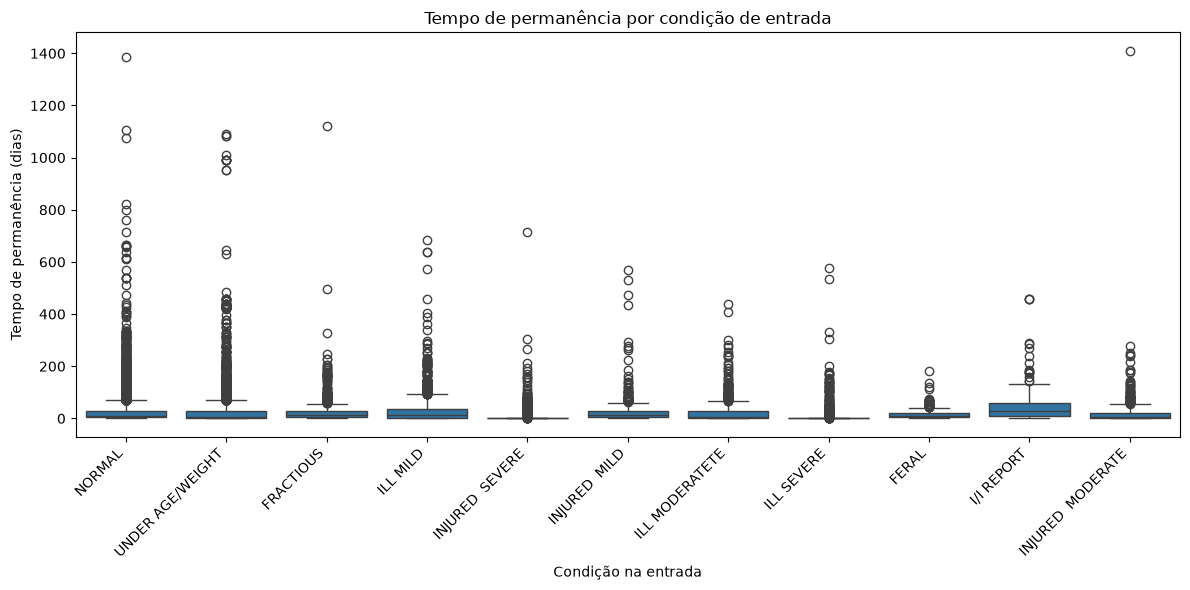

In [34]:
# TEMPO DE PERMANÊNCIA POR CONDIÇÃO


dados_boxplot = df_gatos[
    df_gatos["Intake Condition"].isin(condicoes_principais)
].copy()

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=dados_boxplot,
    x="Intake Condition",
    y="intake_duration"
)

plt.xlabel("Condição na entrada")
plt.ylabel("Tempo de permanência (dias)")
plt.title("Tempo de permanência por condição de entrada")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

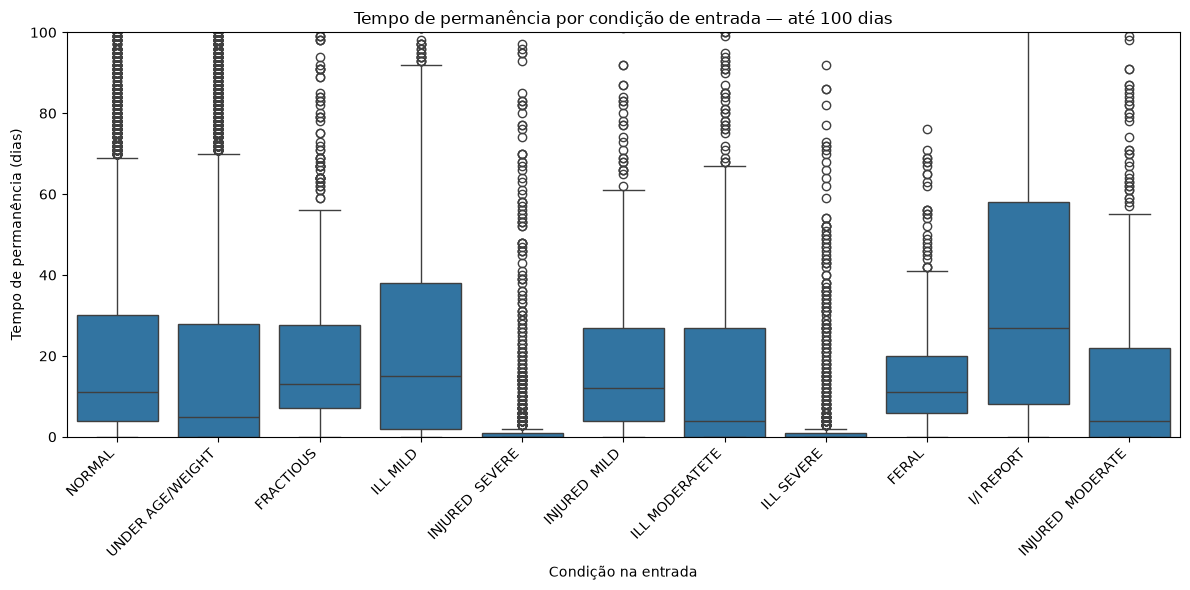

In [ ]:
# ==========================================
# BOXplot — VISÃO ATÉ 100 DIAS
# ==========================================


plt.figure(figsize=(12, 6))

sns.boxplot(
    data=dados_boxplot,
    x="Intake Condition",
    y="intake_duration"
)

plt.ylim(0, 100)

plt.xlabel("Condição na entrada")
plt.ylabel("Tempo de permanência (dias)")
plt.title("Tempo de permanência por condição de entrada — até 100 dias")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# TEMPO DE PERMANÊNCIA POR SEXO
# ==========================================

df_gatos.groupby("Sex")["intake_duration"].agg(
    ["count", "mean", "median"]
).sort_values("median", ascending=False)

,count,mean,median
Sex,,,
Spayed,5357,41.089976,22.0
Neutered,5654,39.285992,21.0
Female,6384,14.962563,3.0
Male,6459,14.079579,3.0
Unknown,3204,7.147628,0.0


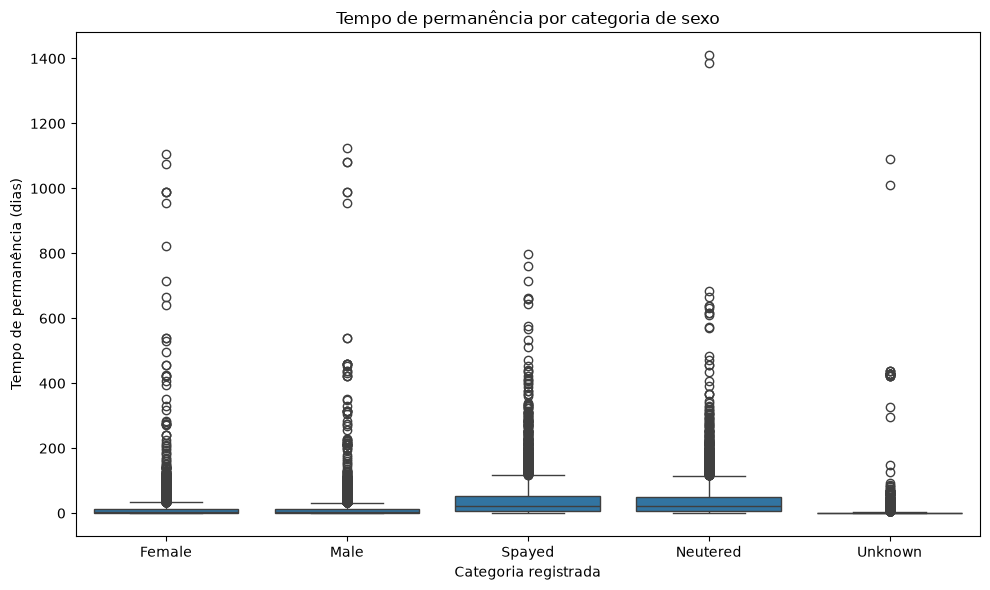

In [37]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_gatos,
    x="Sex",
    y="intake_duration"
)

plt.xlabel("Categoria registrada")
plt.ylabel("Tempo de permanência (dias)")
plt.title("Tempo de permanência por categoria de sexo")

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# TEMPO DE PERMANÊNCIA POR TIPO DE ENTRADA
# ==========================================

df_gatos.groupby("Intake Type")["intake_duration"].agg(
    ["count", "mean", "median"]
).sort_values("median", ascending=False)

,count,mean,median
Intake Type,,,
QUARANTINE,35,32.428571,23.0
WELFARE SEIZED,291,32.838488,16.0
CONFISCATE,118,39.423729,14.0
OWNER SURRENDER,1824,36.718750,14.0
RETURN,243,25.798354,9.0
STRAY,24398,23.005287,7.0
SAFE KEEP,23,18.217391,6.0
"TRAP, NEUTER, RETURN",119,10.991597,2.0
FOSTER,5,1.400000,1.0


In [39]:
# Tipos de entrada com pelo menos 100 gatos

frequencia_tipo = df_gatos["Intake Type"].value_counts()

tipos_principais = frequencia_tipo[
    frequencia_tipo >= 100
].index

print("Tipos de entrada selecionados:")
print(tipos_principais)

Tipos de entrada selecionados:
Index(['STRAY', 'OWNER SURRENDER', 'WELFARE SEIZED', 'RETURN',
       'TRAP, NEUTER, RETURN', 'CONFISCATE'],
      dtype='str', name='Intake Type')


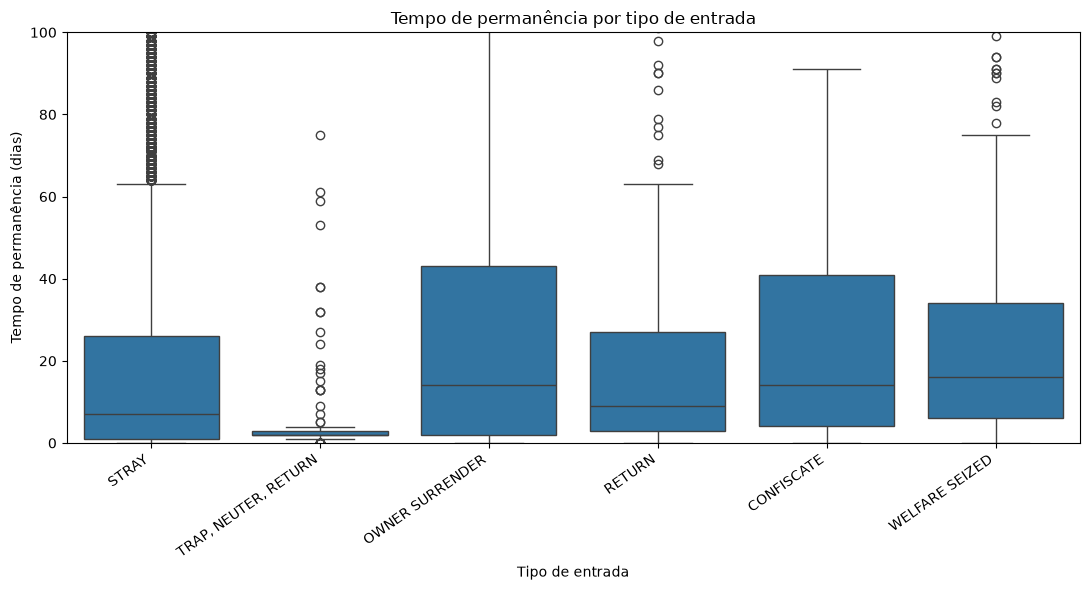

In [ ]:
# ==========================================
# TEMPO DE PERMANÊNCIA POR TIPO DE ENTRADA
# ==========================================

dados_boxplot_tipo = df_gatos[
    df_gatos["Intake Type"].isin(tipos_principais)
].copy()

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=dados_boxplot_tipo,
    x="Intake Type",
    y="intake_duration"
)

plt.ylim(0, 100)

plt.xlabel("Tipo de entrada")
plt.ylabel("Tempo de permanência (dias)")
plt.title("Tempo de permanência por tipo de entrada")

plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# TEMPO DE PERMANÊNCIA POR SUBTIPO DE ENTRADA
# ============================================

df_gatos.groupby("Intake Subtype")["intake_duration"].agg(
    ["count", "mean", "median"]
).sort_values("median", ascending=False)

,count,mean,median
Intake Subtype,,,
CRUELTY,41,53.780488,33.0
EVICTION,45,40.711111,18.0
BORN@SHELT,83,25.807229,16.0
SPCALA,13,34.000000,16.0
ABAN SHLTR,180,26.827778,15.0
POLICE,103,31.611650,14.0
HOSPITAL,64,41.718750,14.0
AT SHELTER,64,38.671875,13.0
OWNER DIED,107,28.149533,13.0


In [42]:
# Subtipos de entrada com pelo menos 100 gatos

frequencia_subtipo = df_gatos["Intake Subtype"].value_counts()

subtipos_principais = frequencia_subtipo[
    frequencia_subtipo >= 100
].index

print("Subtipos de entrada selecionados:")
print(subtipos_principais)

Subtipos de entrada selecionados:
Index(['OTC', 'FIELD', 'TRAP', 'ABAN FIELD', 'ABAN SHLTR', 'ADOPTION',
       'OWNER DIED', 'POLICE'],
      dtype='str', name='Intake Subtype')


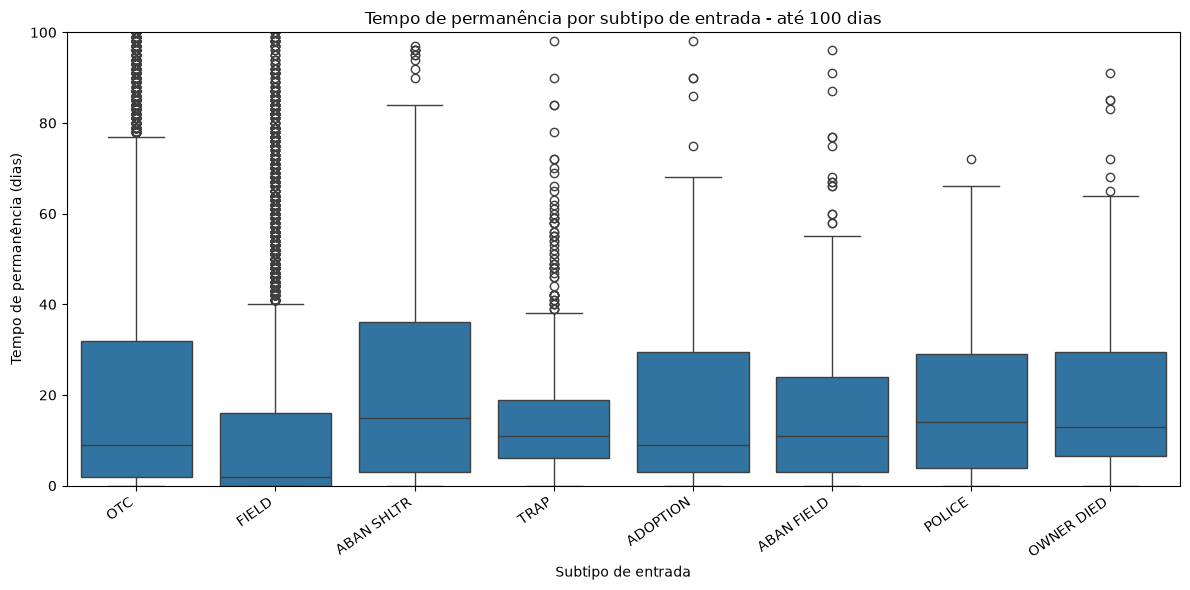

In [ ]:
# =============================================
# TEMPO DE PERMANÊNCIA POR SUBTIPO DE ENTRADA
# =============================================

dados_boxplot_subtipo = df_gatos[
    df_gatos["Intake Subtype"].isin(subtipos_principais)
].copy()

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=dados_boxplot_subtipo,
    x="Intake Subtype",
    y="intake_duration"
)

plt.ylim(0, 100)

plt.xlabel("Subtipo de entrada")
plt.ylabel("Tempo de permanência (dias)")
plt.title("Tempo de permanência por subtipo de entrada - até 100 dias")

plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()

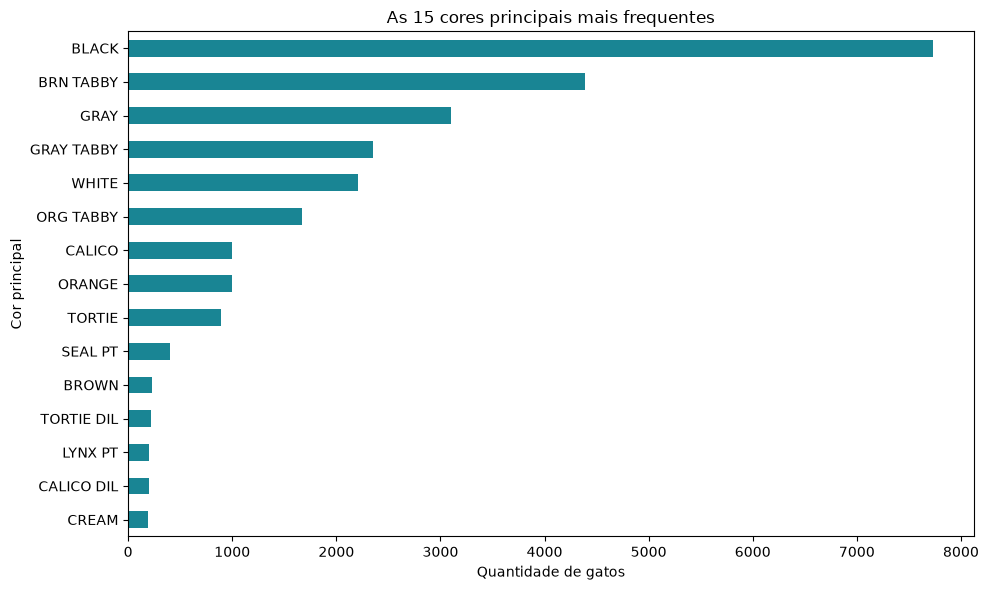

In [ ]:
# ==========================================
# ANÁLISE DA COR PRINCIPAL DOS GATOS
# ==========================================

frequencia_cores = df_gatos["Primary Color"].value_counts()

top_15_cores = frequencia_cores.head(15)

plt.figure(figsize=(10, 6))

top_15_cores.sort_values().plot(
    kind="barh",
    color="#198594"
)

plt.xlabel("Quantidade de gatos")
plt.ylabel("Cor principal")
plt.title("As 15 cores principais mais frequentes")

plt.tight_layout()
plt.show()



In [ ]:
# ==========================================
# COR PRINCIPAL X TEMPO DE PERMANÊNCIA
# ==========================================

# Selecionar as 10 cores mais frequentes
top_10_nomes = df_gatos["Primary Color"].value_counts().head(10).index

# Filtrar os gatos dessas categorias
df_cores = df_gatos[
    df_gatos["Primary Color"].isin(top_10_nomes)
].copy()

# Calcular quantidade, mediana e média por cor
resumo_cores = (
    df_cores.groupby("Primary Color")["intake_duration"]
    .agg(["count", "median", "mean"])
    .sort_values("median", ascending=True)
)

resumo_cores

,count,median,mean
Primary Color,,,
SEAL PT,396,5.0,16.765152
CALICO,990,6.0,22.026263
ORANGE,984,6.0,19.202236
WHITE,2192,6.0,23.675182
ORG TABBY,1656,7.0,24.690821
GRAY,3073,7.0,23.592581
BRN TABBY,4339,7.0,23.746716
BLACK,7656,8.0,25.604754
GRAY TABBY,2337,8.0,25.896448


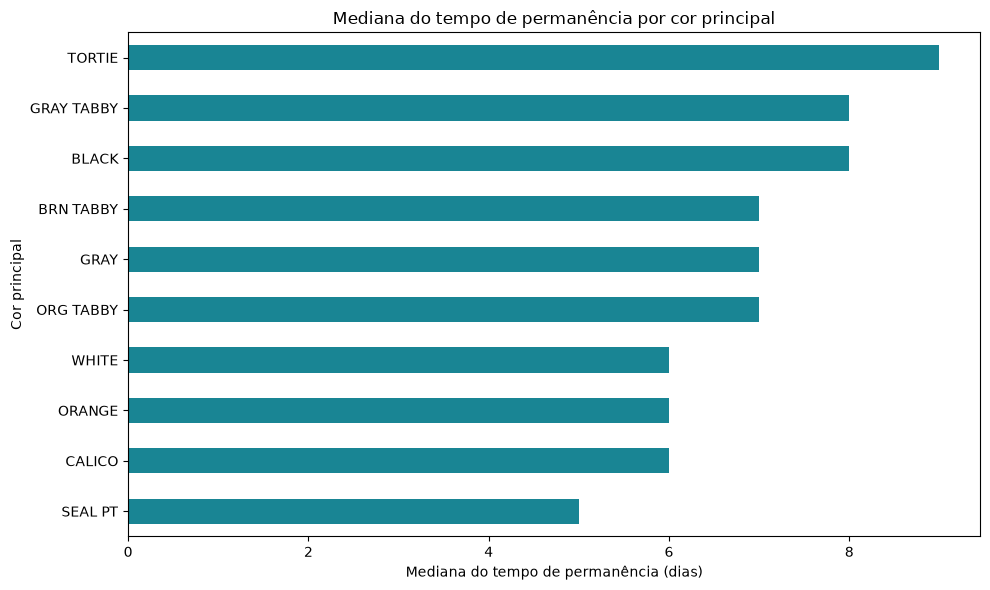

In [ ]:
# ==========================================
# MEDIANA DO TEMPO DE PERMANÊNCIA POR COR
# ==========================================

plt.figure(figsize=(10, 6))

resumo_cores["median"].plot(
    kind="barh",
    color="#198594"
)

plt.xlabel("Mediana do tempo de permanência (dias)")
plt.ylabel("Cor principal")
plt.title("Mediana do tempo de permanência por cor principal")

plt.tight_layout()
plt.show()


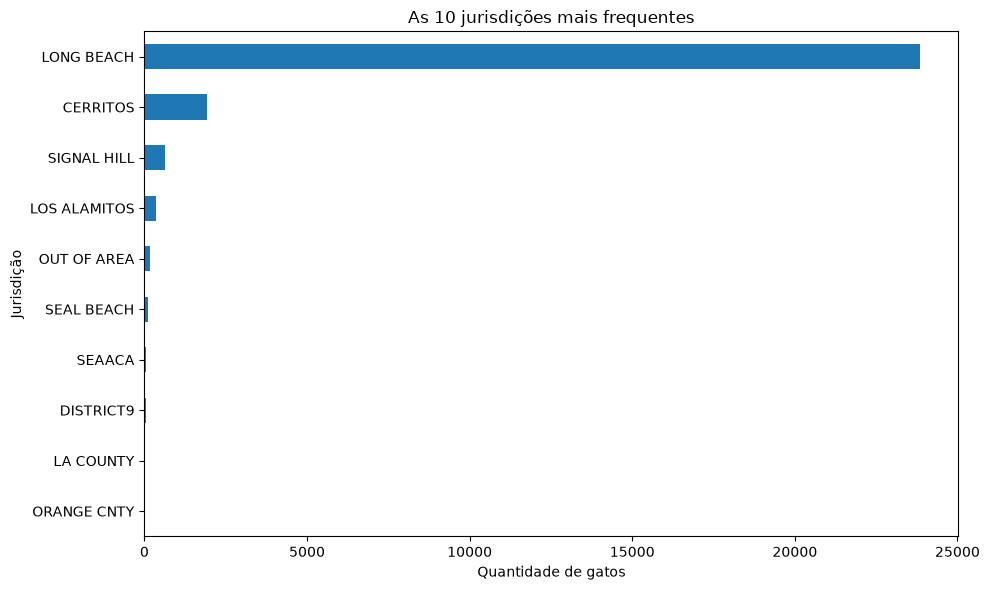

In [ ]:
# ==========================================
# ANÁLISE DA JURISDIÇÃO
# ==========================================

# Contar os registros por jurisdição
frequencia_jurisdicao = df_gatos["Jurisdiction"].value_counts()

# Selecionar as 10 jurisdições mais frequentes
top_10_jurisdicoes = frequencia_jurisdicao.head(10)

# Criar o gráfico
plt.figure(figsize=(10, 6))

top_10_jurisdicoes.sort_values().plot(kind="barh")

plt.xlabel("Quantidade de gatos")
plt.ylabel("Jurisdição")
plt.title("As 10 jurisdições mais frequentes")

plt.tight_layout()
plt.show()


In [ ]:

# ==========================================
# JURISDIÇÃO X TEMPO DE PERMANÊNCIA
# ==========================================

# Contar os gatos por jurisdição
contagem_jurisdicao = df_gatos["Jurisdiction"].value_counts()

# Selecionar jurisdições com pelo menos 100 gatos
jurisdicoes_validas = contagem_jurisdicao[
    contagem_jurisdicao >= 100
].index

# Filtrar os registros dessas jurisdições
df_jurisdicoes = df_gatos[
    df_gatos["Jurisdiction"].isin(jurisdicoes_validas)
].copy()

# Calcular quantidade, mediana e média do tempo de permanência
resumo_jurisdicoes = (
    df_jurisdicoes.groupby("Jurisdiction")["intake_duration"]
    .agg(["count", "median", "mean"])
    .sort_values("median")
)

resumo_jurisdicoes


,count,median,mean
Jurisdiction,,,
CERRITOS,1916,5.5,19.036534
OUT OF AREA,177,6.0,27.259887
LONG BEACH,23612,7.0,23.948924
SEAL BEACH,115,7.0,33.652174
SIGNAL HILL,612,7.0,23.866013
LOS ALAMITOS,367,8.0,25.553134


In [ ]:

# ============================================
# PREPARAÇÃO INICIAL DOS DADOS PARA O MODELO
# ============================================


# Definir as variáveis que poderão ser utilizadas
colunas_modelo = [
    "intake_duration",       # Variável-alvo
    "idade_na_entrada",
    "Sex",
    "Intake Condition",
    "Intake Type",
    "Intake Subtype",
    "Primary Color",
    "Jurisdiction"
]

# Criar uma cópia com as colunas selecionadas
df_modelo = df_gatos[colunas_modelo].copy()

# Remover registros sem o tempo de permanência conhecido
df_modelo = df_modelo.dropna(subset=["intake_duration"])

# Conferir as dimensões e os valores ausentes
print("Dimensões dos dados:", df_modelo.shape)

print("\nValores ausentes por coluna:")
print(df_modelo.isnull().sum())




Dimensões dos dados: (27058, 8)

Valores ausentes por coluna:
intake_duration        0
idade_na_entrada    1247
Sex                    0
Intake Condition       0
Intake Type            0
Intake Subtype       304
Primary Color          0
Jurisdiction           0
dtype: int64


In [ ]:
# ==========================================
# DEFINIÇÃO DE X E y
# ==========================================


# Variáveis utilizadas para fazer a previsão
X = df_modelo.drop(columns=["intake_duration"])

# Variáveis que queremos prever
y = df_modelo["intake_duration"]

print("Dimensões de X:", X.shape)
print("Dimensões de y:", y.shape)

print("\nPrimeuras linhas das variáveis preditoras:")
display(X.head())

print("\nPrimeiros valores da variável-alvo")
display(y.head())

Dimensões de X: (27058, 7)
Dimensões de y: (27058,)

Primeuras linhas das variáveis preditoras:


,idade_na_entrada,Sex,Intake Condition,Intake Type,Intake Subtype,Primary Color,Jurisdiction
4,0.208077,Female,NORMAL,STRAY,OTC,TORTIE,LONG BEACH
7,0.082136,Male,UNDER AGE/WEIGHT,STRAY,OTC,BRN TABBY,LONG BEACH
12,3.000684,Spayed,FRACTIOUS,STRAY,OTC,BRN TABBY,LONG BEACH
13,3.000684,Neutered,NORMAL,STRAY,OTC,GRAY,LONG BEACH
15,0.038330,Male,UNDER AGE/WEIGHT,STRAY,OTC,BLACK,LONG BEACH



Primeiros valores da variável-alvo


4       6.0
7      14.0
12    165.0
13     12.0
15      0.0
Name: intake_duration, dtype: float64

In [ ]:
# ==========================================
# SEPARAÇÃO DOS DADOS: TREINO E TESTE
# ==========================================


from sklearn.model_selection import train_test_split

# Separar os dados em 80% para treino e 20% para teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Conferir as dimensões

print("Dados de treinamento:")
print("X_treino:", X_treino.shape)
print("y_treino:", y_treino.shape)

print("\nDados de teste")
print("X_teste:",X_teste.shape)
print("y_teste:",y_teste.shape)

Dados de treinamento:
X_treino: (21646, 7)
y_treino: (21646,)

Dados de teste
X_teste: (5412, 7)
y_teste: (5412,)


In [ ]:
# ==========================================
# PREPARAÇÃO DAS VARIÁVEIS
# ==========================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Separar as colunas por tipo
colunas_numericas = ["idade_na_entrada"]

colunas_categoricas = [
    "Sex",
    "Intake Condition",
    "Intake Type",
    "Intake Subtype",
    "Primary Color",
    "Jurisdiction"
]

# Preparação das variáveis numéricas
pipeline_numerico = Pipeline(steps=[
    ("imputador", SimpleImputer(strategy="median"))
])

# Preparação das variáveis categoricas 
pipeline_categorico = Pipeline(steps=[
    ("imputador", SimpleImputer(
        strategy="constant",
        fill_value="Não informado"

    )),
    ("codificador", OneHotEncoder(handle_unknown="ignore"))

])

# Combinar os dois tratamentos
preprocessador = ColumnTransformer(transformers=[
    ("numerico", pipeline_numerico, colunas_numericas),
    ("categorico", pipeline_categorico, colunas_categoricas)
])

print("Pré-processador criado com sucesso!")


Pré-processador criado com sucesso!


In [53]:

# ==========================================
# APLICAR O PRÉ-PROCESSAMENTO
# ==========================================

# Aprender os tratamentos e transformar o treino
X_treino_preparado = preprocessador.fit_transform(X_treino)

# Aplicar os mesmos tratamentos ao teste
X_teste_preparado = preprocessador.transform(X_teste)

# Conferir os resultados
print("Formato do treino antes:", X_treino.shape)
print("Formato do treino depois:", X_treino_preparado.shape)

print("\nFormato do teste antes:", X_teste.shape)
print("Formato do teste depois:", X_teste_preparado.shape)


Formato do treino antes: (21646, 7)
Formato do treino depois: (21646, 144)

Formato do teste antes: (5412, 7)
Formato do teste depois: (5412, 144)


In [54]:

# ==========================================
# TREINAMENTO DO MODELO
# ==========================================

from sklearn.linear_model import LinearRegression

# Criar o modelo
modelo = LinearRegression()

# Treinar com os dados preparados
modelo.fit(X_treino_preparado, y_treino)

print("Modelo de Regressão Linear treinado com sucesso!")


Modelo de Regressão Linear treinado com sucesso!


In [55]:

# ==========================================
# PRIMEIRAS PREVISÕES DO MODELO
# ==========================================

# Gerar previsões para os dados de teste
y_previsto = modelo.predict(X_teste_preparado)

# Comparar valores reais com valores previstos
comparacao = pd.DataFrame({
    "Tempo real (dias)": y_teste,
    "Tempo previsto (dias)": y_previsto
})

# Mostrar os primeiros 10 resultados
display(comparacao.head(10).round(2))


,Tempo real (dias),Tempo previsto (dias)
50843,2.0,35.74
48484,2.0,35.18
38765,33.0,46.70
19855,4.0,46.05
29983,17.0,6.89
28936,16.0,41.68
20470,3.0,13.84
22937,2.0,23.25
7874,30.0,32.91
37469,15.0,20.14


In [56]:

# ==========================================
# AVALIAÇÃO DO MODELO
# ==========================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Calcular as métricas
mae = mean_absolute_error(y_teste, y_previsto)
mse = mean_squared_error(y_teste, y_previsto)
rmse = np.sqrt(mse)
r2 = r2_score(y_teste, y_previsto)

# Exibir os resultados
print(f"MAE:  {mae:.2f} dias")
print(f"MSE:  {mse:.2f}")
print(f"RMSE: {rmse:.2f} dias")
print(f"R²:   {r2:.4f}")


MAE:  22.51 dias
MSE:  2240.26
RMSE: 47.33 dias
R²:   0.0798


In [57]:

# ==========================================
# EXPERIMENTO 2: REGRESSÃO LINEAR COM LOG
# ==========================================

# Transformar o tempo de permanência
y_treino_log = np.log1p(y_treino)

# Criar e treinar a segunda versão
modelo_log = LinearRegression()
modelo_log.fit(X_treino_preparado, y_treino_log)

# Prever na escala logarítmica
y_previsto_log = modelo_log.predict(X_teste_preparado)

# Voltar para a escala original: dias
y_previsto_log_dias = np.expm1(y_previsto_log)

# Evitar previsões negativas de dias
y_previsto_log_dias = np.maximum(y_previsto_log_dias, 0)

print("Segundo modelo treinado com sucesso!")


Segundo modelo treinado com sucesso!


In [58]:

# ==========================================
# COMPARAÇÃO DOS DOIS MODELOS
# ==========================================

mae_log = mean_absolute_error(y_teste, y_previsto_log_dias)
mse_log = mean_squared_error(y_teste, y_previsto_log_dias)
rmse_log = np.sqrt(mse_log)
r2_log = r2_score(y_teste, y_previsto_log_dias)

comparacao_modelos = pd.DataFrame({
    "Métrica": ["MAE (dias)", "MSE", "RMSE (dias)", "R²"],
    "Regressão Linear original": [mae, mse, rmse, r2],
    "Regressão Linear com log": [mae_log, mse_log, rmse_log, r2_log]
})

display(comparacao_modelos.round(4))


,Métrica,Regressão Linear original,Regressão Linear com log
0,MAE (dias),22.5120,18.6702
1,MSE,2240.2621,2412.7207
2,RMSE (dias),47.3314,49.1195
3,R²,0.0798,0.0090


In [59]:

# ==========================================
# BASELINE: PREVER SEMPRE A MEDIANA
# ==========================================

# Calcular a mediana somente no conjunto de treinamento
mediana_treino = y_treino.median()

# Repetir essa previsão para todos os registros de teste
y_baseline = np.full(len(y_teste), mediana_treino)

# Calcular as métricas
mae_baseline = mean_absolute_error(y_teste, y_baseline)
mse_baseline = mean_squared_error(y_teste, y_baseline)
rmse_baseline = np.sqrt(mse_baseline)
r2_baseline = r2_score(y_teste, y_baseline)

print(f"Mediana do treino: {mediana_treino:.2f} dias")
print(f"MAE baseline:      {mae_baseline:.2f} dias")
print(f"MSE baseline:      {mse_baseline:.2f}")
print(f"RMSE baseline:     {rmse_baseline:.2f} dias")
print(f"R² baseline:       {r2_baseline:.4f}")


Mediana do treino: 7.00 dias
MAE baseline:      20.99 dias
MSE baseline:      2681.89
RMSE baseline:     51.79 dias
R² baseline:       -0.1016


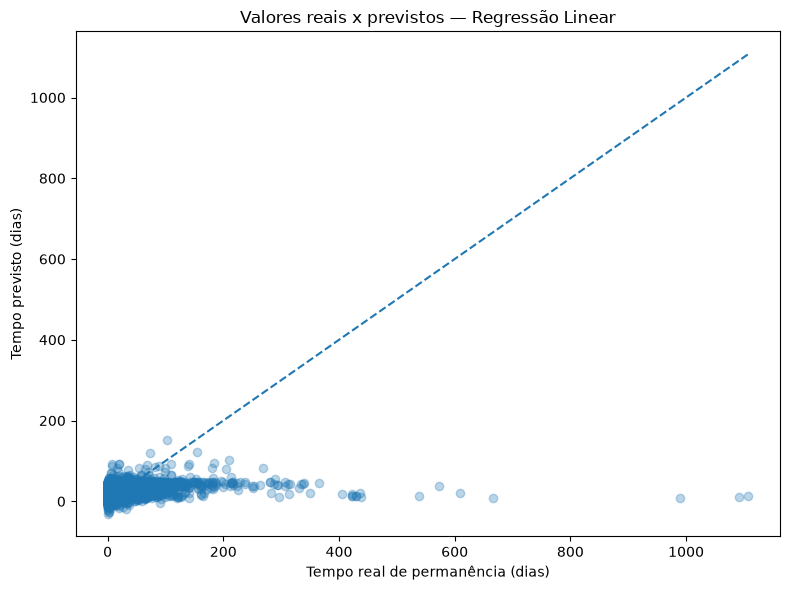

In [60]:

# ==========================================
# VALORES REAIS X VALORES PREVISTOS
# ==========================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_teste,
    y_previsto,
    alpha=0.3
)

# Linha de referência: previsão perfeita
limite = max(y_teste.max(), y_previsto.max())

plt.plot(
    [0, limite],
    [0, limite],
    linestyle="--"
)

plt.xlabel("Tempo real de permanência (dias)")
plt.ylabel("Tempo previsto (dias)")
plt.title("Valores reais x previstos — Regressão Linear")
plt.tight_layout()
plt.show()


In [61]:

# ==========================================
# ERROS POR FAIXA DE TEMPO REAL
# ==========================================

analise_erros = pd.DataFrame({
    "tempo_real": y_teste,
    "tempo_previsto": y_previsto
})

# Calcular o erro absoluto
analise_erros["erro_absoluto"] = (
    analise_erros["tempo_real"]
    - analise_erros["tempo_previsto"]
).abs()

# Agrupar os registros por faixa de permanência
analise_erros["faixa_tempo"] = pd.cut(
    analise_erros["tempo_real"],
    bins=[-1, 7, 30, 90, 365, float("inf")],
    labels=[
        "0 a 7 dias",
        "8 a 30 dias",
        "31 a 90 dias",
        "91 a 365 dias",
        "Mais de 365 dias"
    ]
)

# Resumir os erros por faixa
resumo_erros = (
    analise_erros.groupby("faixa_tempo", observed=False)
    .agg(
        quantidade=("tempo_real", "count"),
        mediana_real=("tempo_real", "median"),
        mediana_prevista=("tempo_previsto", "median"),
        erro_medio=("erro_absoluto", "mean")
    )
)

display(resumo_erros.round(2))


,quantidade,mediana_real,mediana_prevista,erro_medio
faixa_tempo,,,,
0 a 7 dias,2829,1.0,14.94,15.84
8 a 30 dias,1387,15.0,28.86,15.47
31 a 90 dias,921,48.0,39.20,21.00
91 a 365 dias,259,122.0,41.59,104.85
Mais de 365 dias,16,437.5,13.38,566.99


In [62]:

# ==========================================
# VIABILIDADE: PREVISÃO DO DESFECHO
# ==========================================

frequencia_desfechos = df_gatos["Outcome Type"].value_counts(
    dropna=False
)

print("Quantidade de registros por desfecho:")
display(frequencia_desfechos.to_frame(name="quantidade"))

print("\nTotal de gatos:", len(df_gatos))
print(
    "Desfechos não informados:",
    df_gatos["Outcome Type"].isna().sum()
)


Quantidade de registros por desfecho:


,quantidade
Outcome Type,
RESCUE,7896
ADOPTION,6732
EUTHANASIA,5011
TRANSFER,2635
"SHELTER, NEUTER, RETURN",1395
COMMUNITY CAT,1132
DIED,774
RETURN TO OWNER,573
NaN,245



Total de gatos: 27295
Desfechos não informados: 245


In [ ]:
# ==========================================
# NOVO ALVO: ADOÇÃO OU OUTRO DESFECHO
# ==========================================


# Manter somente registros com desfecho informado
df_classificacao = df_gatos.dropna(
    subset=["Outcome Type"]
).copy()

# Criar a variável-alvo binária
df_classificacao["adotado"] = (
    df_classificacao["Outcome Type"] == "ADOPTION"
).astype(int)

# Conferir a distribuição das classes
print("Distribuição da variável-alvo:")

display(
    df_classificacao["adotado"]
    .value_counts()
    .rename(index={
        1: "ADOPTION",
        0: "OUTRO DESFECHO"
    })
    .to_frame(name="quantidade")
)

print("\nProporção das classes (%):")

display(
    (
        df_classificacao["adotado"]
        .value_counts(normalize=True)
        .mul(100)
        .rename(index={
            1: "ADOPTION",
            0: "OUTRO DESFECHO"
        })
        .to_frame(name="percentual")
        .round(2)
    )
)


Distribuição da variável-alvo:


,quantidade
adotado,
OUTRO DESFECHO,20318
ADOPTION,6732



Proporção das classes (%):


,percentual
adotado,
OUTRO DESFECHO,75.11
ADOPTION,24.89


In [ ]:
# ==========================================
# PREPARAÇÃO DOS DADOS PARA CLASSIFICAÇÃO
# ==========================================


# Variáveis conhecidas no momento da entrada
colunas_preditoras = [
    "idade_na_entrada",
    "Sex",
    "Intake Condition",
    "Intake Type",
    "Intake Subtype",
    "Primary Color",
    "Jurisdiction"
]

# Definir as variáveis preditoras e o alvo
X_class = df_classificacao[colunas_preditoras].copy()
y_class = df_classificacao["adotado"].copy()

print("Dimensões de X:", X_class.shape)
print("Dimensões de y:", y_class.shape)

print("\nDistribuição do alvo:")
print(y_class.value_counts())


Dimensões de X: (27050, 7)
Dimensões de y: (27050,)

Distribuição do alvo:
adotado
0    20318
1     6732
Name: count, dtype: int64


In [ ]:
# ==========================================
# DIVISÃO TREINO E TESTE — CLASSIFICAÇÃO
# ==========================================



from sklearn.model_selection import train_test_split

X_class_treino, X_class_teste, y_class_treino, y_class_teste = (
    train_test_split(
        X_class,
        y_class,
        test_size=0.20,
        random_state=42,
        stratify=y_class
    )
)

print("Treinamento:", X_class_treino.shape)
print("Teste:", X_class_teste.shape)

print("\nProporção de adoção no treino:")
print(y_class_treino.mean().round(4))

print("\nProporção de adoção no teste:")
print(y_class_teste.mean().round(4))


Treinamento: (21640, 7)
Teste: (5410, 7)

Proporção de adoção no treino:
0.2489

Proporção de adoção no teste:
0.2488


In [ ]:
# ==========================================
# PRÉ-PROCESSAMENTO PARA CLASSIFICAÇÃO
# ==========================================


from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

colunas_numericas = ["idade_na_entrada"]

colunas_categoricas = [
    "Sex",
    "Intake Condition",
    "Intake Type",
    "Intake Subtype",
    "Primary Color",
    "Jurisdiction"
]

pipeline_numerico_class = Pipeline(steps=[
    ("imputador", SimpleImputer(strategy="median"))
])

pipeline_categorico_class = Pipeline(steps=[
    ("imputador", SimpleImputer(
        strategy="constant",
        fill_value="Não informado"
    )),
    ("codificador", OneHotEncoder(handle_unknown="ignore"))
])

preprocessador_class = ColumnTransformer(transformers=[
    ("numerico", pipeline_numerico_class, colunas_numericas),
    ("categorico", pipeline_categorico_class, colunas_categoricas)
])

# Ajustar somente com o treino
X_class_treino_preparado = preprocessador_class.fit_transform(
    X_class_treino
)

# Aplicar ao teste sem reajustar
X_class_teste_preparado = preprocessador_class.transform(
    X_class_teste
)

print("Formato do treino:", X_class_treino_preparado.shape)
print("Formato do teste:", X_class_teste_preparado.shape)


Formato do treino: (21640, 146)
Formato do teste: (5410, 146)


In [ ]:
# ==========================================
# TREINAMENTO DA REGRESSÃO LOGÍSTICA
# ==========================================

from sklearn.linear_model import LogisticRegression

# Criar o classificador
modelo_logistico = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Treinar usando os dados preparados
modelo_logistico.fit(
    X_class_treino_preparado,
    y_class_treino
)

print("Regressão Logística treinada com sucesso!")


Regressão Logística treinada com sucesso!


Acurácia:  0.8161
Precisão:  0.6191
Recall:    0.6776
F1-score:  0.6470

Relatório de classificação:
                precision    recall  f1-score   support

Outro desfecho       0.89      0.86      0.88      4064
        Adoção       0.62      0.68      0.65      1346

      accuracy                           0.82      5410
     macro avg       0.75      0.77      0.76      5410
  weighted avg       0.82      0.82      0.82      5410



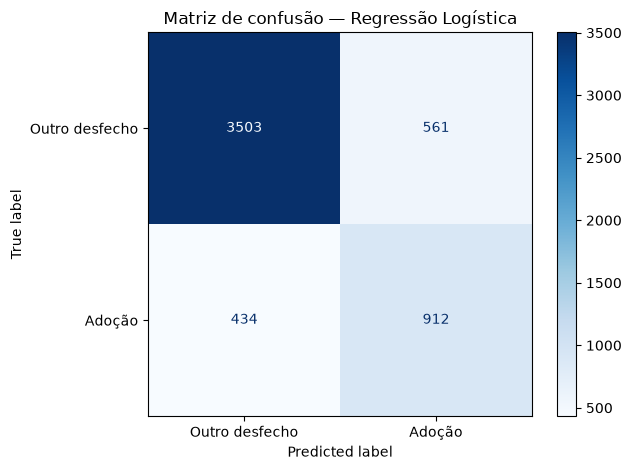

In [ ]:
# ==========================================
# AVALIAÇÃO DA REGRESSÃO LOGÍSTICA
# ==========================================


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Prever os desfechos dos gatos do conjunto de teste
y_class_previsto = modelo_logistico.predict(
    X_class_teste_preparado
)

# Calcular as métricas
acuracia = accuracy_score(y_class_teste, y_class_previsto)
precisao = precision_score(y_class_teste, y_class_previsto, zero_division=0)
recall = recall_score(y_class_teste, y_class_previsto, zero_division=0)
f1 = f1_score(y_class_teste, y_class_previsto, zero_division=0)

print(f"Acurácia:  {acuracia:.4f}")
print(f"Precisão:  {precisao:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nRelatório de classificação:")
print(classification_report(
    y_class_teste,
    y_class_previsto,
    target_names=["Outro desfecho", "Adoção"],
    zero_division=0
))

# Matriz de confusão
matriz = confusion_matrix(y_class_teste, y_class_previsto)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Outro desfecho", "Adoção"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusão — Regressão Logística")
plt.tight_layout()
plt.show()


In [ ]:
# ==========================================
# REGRESSÃO LOGÍSTICA BALANCEADA
# ==========================================


modelo_logistico_balanceado = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight="balanced"
)

modelo_logistico_balanceado.fit(
    X_class_treino_preparado,
    y_class_treino
)

# Previsões no mesmo conjunto de teste
y_previsto_balanceado = (
    modelo_logistico_balanceado.predict(
        X_class_teste_preparado
    )
)

print("Modelo balanceado treinado com sucesso!")


Modelo balanceado treinado com sucesso!


Acurácia:  0.7983
Precisão:  0.5679
Recall:    0.7920
F1-score:  0.6615

Relatório de classificação:
                precision    recall  f1-score   support

Outro desfecho       0.92      0.80      0.86      4064
        Adoção       0.57      0.79      0.66      1346

      accuracy                           0.80      5410
     macro avg       0.74      0.80      0.76      5410
  weighted avg       0.83      0.80      0.81      5410



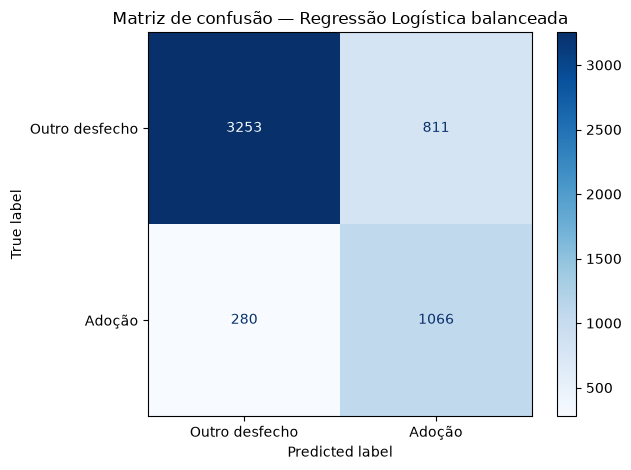

In [ ]:
# ==========================================
# AVALIAÇÃO DO MODELO BALANCEADO
# ==========================================


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Calcular métricas do modelo balanceado
acuracia_bal = accuracy_score(
    y_class_teste, y_previsto_balanceado
)
precisao_bal = precision_score(
    y_class_teste, y_previsto_balanceado, zero_division=0
)
recall_bal = recall_score(
    y_class_teste, y_previsto_balanceado, zero_division=0
)
f1_bal = f1_score(
    y_class_teste, y_previsto_balanceado, zero_division=0
)

print(f"Acurácia:  {acuracia_bal:.4f}")
print(f"Precisão:  {precisao_bal:.4f}")
print(f"Recall:    {recall_bal:.4f}")
print(f"F1-score:  {f1_bal:.4f}")

print("\nRelatório de classificação:")
print(classification_report(
    y_class_teste,
    y_previsto_balanceado,
    target_names=["Outro desfecho", "Adoção"],
    zero_division=0
))

# Matriz de confusão
matriz_bal = confusion_matrix(
    y_class_teste, y_previsto_balanceado
)

disp_bal = ConfusionMatrixDisplay(
    confusion_matrix=matriz_bal,
    display_labels=["Outro desfecho", "Adoção"]
)

disp_bal.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusão — Regressão Logística balanceada")
plt.tight_layout()
plt.show()


In [ ]:
# ==========================================
# COMPARAÇÃO DOS MODELOS DE CLASSIFICAÇÃO
# ==========================================


comparacao_classificadores = pd.DataFrame({
    "Métrica": [
        "Acurácia",
        "Precisão — adoção",
        "Recall — adoção",
        "F1-score — adoção"
    ],
    "Regressão Logística": [
        acuracia,
        precisao,
        recall,
        f1
    ],
    "Regressão Logística balanceada": [
        acuracia_bal,
        precisao_bal,
        recall_bal,
        f1_bal
    ]
})

display(
    comparacao_classificadores.round(4)
)


,Métrica,Regressão Logística,Regressão Logística balanceada
0,Acurácia,0.8161,0.7983
1,Precisão — adoção,0.6191,0.5679
2,Recall — adoção,0.6776,0.7920
3,F1-score — adoção,0.6470,0.6615


In [72]:

# ==========================================
# BASELINE PARA CLASSIFICAÇÃO
# ==========================================

from sklearn.dummy import DummyClassifier

modelo_baseline_class = DummyClassifier(
    strategy="most_frequent"
)

modelo_baseline_class.fit(
    X_class_treino_preparado,
    y_class_treino
)

y_baseline_class = modelo_baseline_class.predict(
    X_class_teste_preparado
)

acuracia_base = accuracy_score(
    y_class_teste, y_baseline_class
)

precisao_base = precision_score(
    y_class_teste, y_baseline_class, zero_division=0
)

recall_base = recall_score(
    y_class_teste, y_baseline_class, zero_division=0
)

f1_base = f1_score(
    y_class_teste, y_baseline_class, zero_division=0
)

print(f"Acurácia baseline: {acuracia_base:.4f}")
print(f"Precisão baseline: {precisao_base:.4f}")
print(f"Recall baseline:   {recall_base:.4f}")
print(f"F1-score baseline: {f1_base:.4f}")


Acurácia baseline: 0.7512
Precisão baseline: 0.0000
Recall baseline:   0.0000
F1-score baseline: 0.0000


In [73]:

# ==========================================
# COMPARAÇÃO FINAL DOS CLASSIFICADORES
# ==========================================

comparacao_final = pd.DataFrame({
    "Modelo": [
        "Baseline",
        "Regressão Logística",
        "Regressão Logística balanceada"
    ],
    "Acurácia": [
        acuracia_base,
        acuracia,
        acuracia_bal
    ],
    "Precisão — adoção": [
        precisao_base,
        precisao,
        precisao_bal
    ],
    "Recall — adoção": [
        recall_base,
        recall,
        recall_bal
    ],
    "F1-score — adoção": [
        f1_base,
        f1,
        f1_bal
    ]
})

display(
    comparacao_final.set_index("Modelo").round(4)
)


,Acurácia,Precisão — adoção,Recall — adoção,F1-score — adoção
Modelo,,,,
Baseline,0.7512,0.0000,0.0000,0.0000
Regressão Logística,0.8161,0.6191,0.6776,0.6470
Regressão Logística balanceada,0.7983,0.5679,0.7920,0.6615


In [74]:

# ==========================================
# EXPERIMENTO: AJUSTE DO LIMIAR
# ==========================================

# Obter probabilidades da classe ADOPTION (classe 1)
probabilidades_adocao = (
    modelo_logistico_balanceado.predict_proba(
        X_class_teste_preparado
    )[:, 1]
)

# Testar um limiar de 0,40
limiar = 0.40

y_previsto_limiar = (
    probabilidades_adocao >= limiar
).astype(int)

# Calcular métricas
acuracia_limiar = accuracy_score(
    y_class_teste, y_previsto_limiar
)

precisao_limiar = precision_score(
    y_class_teste, y_previsto_limiar, zero_division=0
)

recall_limiar = recall_score(
    y_class_teste, y_previsto_limiar, zero_division=0
)

f1_limiar = f1_score(
    y_class_teste, y_previsto_limiar, zero_division=0
)

print(f"Limiar:    {limiar:.2f}")
print(f"Acurácia:  {acuracia_limiar:.4f}")
print(f"Precisão:  {precisao_limiar:.4f}")
print(f"Recall:    {recall_limiar:.4f}")
print(f"F1-score:  {f1_limiar:.4f}")


Limiar:    0.40
Acurácia:  0.7791
Precisão:  0.5371
Recall:    0.8128
F1-score:  0.6468


In [75]:
from sklearn.model_selection import train_test_split

# Primeiro: separa 20% para o teste final
X_temp, X_class_teste, y_temp, y_class_teste = train_test_split(
    X_class,
    y_class,
    test_size=0.20,
    random_state=42,
    stratify=y_class
)

# Segundo: divide os 80% restantes em treino e validação
X_class_treino, X_class_validacao, y_class_treino, y_class_validacao = train_test_split(
    X_temp,
    y_temp,
    test_size=0.25,
    random_state=42,
    stratify=y_temp
)

print("Treino:", X_class_treino.shape)
print("Validação:", X_class_validacao.shape)
print("Teste:", X_class_teste.shape)

Treino: (16230, 7)
Validação: (5410, 7)
Teste: (5410, 7)


In [76]:
# Ajusta o pré-processamento usando somente os dados de treino
X_class_treino_preparado = preprocessador_class.fit_transform(
    X_class_treino
)

# Aplica as mesmas transformações na validação e no teste
X_class_validacao_preparado = preprocessador_class.transform(
    X_class_validacao
)

X_class_teste_preparado = preprocessador_class.transform(
    X_class_teste
)

print("Treino preparado:", X_class_treino_preparado.shape)
print("Validação preparada:", X_class_validacao_preparado.shape)
print("Teste preparado:", X_class_teste_preparado.shape)

Treino preparado: (16230, 142)
Validação preparada: (5410, 142)
Teste preparado: (5410, 142)


In [77]:
from sklearn.linear_model import LogisticRegression

# Cria o modelo
modelo_logistico = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Treina usando somente os dados de treino
modelo_logistico.fit(
    X_class_treino_preparado,
    y_class_treino
)

print("Treinamento concluído!")

Treinamento concluído!


In [78]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Faz previsões para os dados de validação
y_validacao_previsto = modelo_logistico.predict(
    X_class_validacao_preparado
)

# Calcula as métricas
print("Acurácia:", round(
    accuracy_score(y_class_validacao, y_validacao_previsto), 4
))

print("Precisão:", round(
    precision_score(y_class_validacao, y_validacao_previsto, zero_division=0), 4
))

print("Recall:", round(
    recall_score(y_class_validacao, y_validacao_previsto, zero_division=0), 4
))

print("F1-score:", round(
    f1_score(y_class_validacao, y_validacao_previsto, zero_division=0), 4
))

print("\nRelatório de classificação:")
print(classification_report(
    y_class_validacao,
    y_validacao_previsto,
    labels=[0, 1],
    target_names=["Outro desfecho", "Adoção"],
    zero_division=0
))

Acurácia: 0.8257
Precisão: 0.6418
Recall: 0.6776
F1-score: 0.6592

Relatório de classificação:
                precision    recall  f1-score   support

Outro desfecho       0.89      0.87      0.88      4064
        Adoção       0.64      0.68      0.66      1346

      accuracy                           0.83      5410
     macro avg       0.77      0.78      0.77      5410
  weighted avg       0.83      0.83      0.83      5410



In [79]:
# Cria o modelo balanceado
modelo_logistico_balanceado = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight="balanced"
)

# Treina somente com os dados de treino
modelo_logistico_balanceado.fit(
    X_class_treino_preparado,
    y_class_treino
)

# Faz previsões no conjunto de validação
y_validacao_balanceado = modelo_logistico_balanceado.predict(
    X_class_validacao_preparado
)

# Avalia os resultados
print("Acurácia:", round(
    accuracy_score(y_class_validacao, y_validacao_balanceado), 4
))
print("Precisão:", round(
    precision_score(y_class_validacao, y_validacao_balanceado, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_class_validacao, y_validacao_balanceado, zero_division=0), 4
))
print("F1-score:", round(
    f1_score(y_class_validacao, y_validacao_balanceado, zero_division=0), 4
))

print("\nRelatório de classificação:")
print(classification_report(
    y_class_validacao,
    y_validacao_balanceado,
    labels=[0, 1],
    target_names=["Outro desfecho", "Adoção"],
    zero_division=0
))

Acurácia: 0.8102
Precisão: 0.5885
Recall: 0.7883
F1-score: 0.6739

Relatório de classificação:
                precision    recall  f1-score   support

Outro desfecho       0.92      0.82      0.87      4064
        Adoção       0.59      0.79      0.67      1346

      accuracy                           0.81      5410
     macro avg       0.75      0.80      0.77      5410
  weighted avg       0.84      0.81      0.82      5410



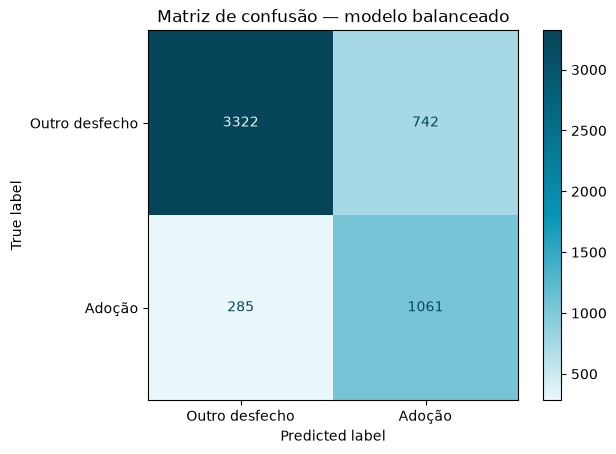

In [103]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

matriz_validacao = confusion_matrix(
    y_class_validacao,
    y_validacao_balanceado,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_validacao,
    display_labels=["Outro desfecho", "Adoção"]
)
azul_miau = LinearSegmentedColormap.from_list(
    "azul_miau",
    ["#EAF7FA", "#0795B5", "#06445A"]
)

disp.plot(
    values_format="d",
    cmap=azul_miau,
    colorbar=True
)


plt.title("Matriz de confusão — modelo balanceado")
plt.show()

In [81]:
comparacao_validacao = pd.DataFrame({
    "Modelo": [
        "Regressão Logística",
        "Regressão Logística Balanceada"
    ],
    "Acurácia": [
        accuracy_score(y_class_validacao, y_validacao_previsto),
        accuracy_score(y_class_validacao, y_validacao_balanceado)
    ],
    "Precisão": [
        precision_score(y_class_validacao, y_validacao_previsto, zero_division=0),
        precision_score(y_class_validacao, y_validacao_balanceado, zero_division=0)
    ],
    "Recall": [
        recall_score(y_class_validacao, y_validacao_previsto, zero_division=0),
        recall_score(y_class_validacao, y_validacao_balanceado, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_class_validacao, y_validacao_previsto, zero_division=0),
        f1_score(y_class_validacao, y_validacao_balanceado, zero_division=0)
    ]
})

comparacao_validacao.round(4)

,Modelo,Acurácia,Precisão,Recall,F1-score
0,Regressão Logística,0.8257,0.6418,0.6776,0.6592
1,Regressão Logística Balanceada,0.8102,0.5885,0.7883,0.6739


In [82]:
# Previsões finais no conjunto de teste
y_teste_previsto = modelo_logistico_balanceado.predict(
    X_class_teste_preparado
)

# Métricas finais
print("Acurácia:", round(
    accuracy_score(y_class_teste, y_teste_previsto), 4
))

print("Precisão:", round(
    precision_score(y_class_teste, y_teste_previsto, zero_division=0), 4
))

print("Recall:", round(
    recall_score(y_class_teste, y_teste_previsto, zero_division=0), 4
))

print("F1-score:", round(
    f1_score(y_class_teste, y_teste_previsto, zero_division=0), 4
))

print("\nRelatório de classificação:")
print(classification_report(
    y_class_teste,
    y_teste_previsto,
    labels=[0, 1],
    target_names=["Outro desfecho", "Adoção"],
    zero_division=0
))

Acurácia: 0.7994
Precisão: 0.5702
Recall: 0.7875
F1-score: 0.6615

Relatório de classificação:
                precision    recall  f1-score   support

Outro desfecho       0.92      0.80      0.86      4064
        Adoção       0.57      0.79      0.66      1346

      accuracy                           0.80      5410
     macro avg       0.74      0.80      0.76      5410
  weighted avg       0.83      0.80      0.81      5410



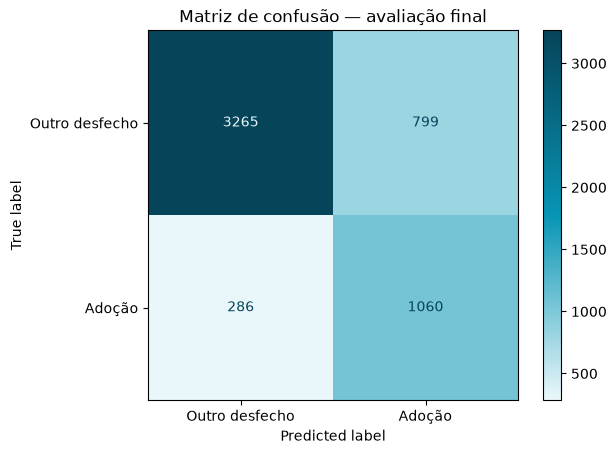

In [104]:


matriz_teste = confusion_matrix(
    y_class_teste,
    y_teste_previsto,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_teste,
    display_labels=["Outro desfecho", "Adoção"]
)
azul_miau = LinearSegmentedColormap.from_list(
    "azul_miau",
    ["#EAF7FA", "#0795B5", "#06445A"]
)

disp.plot(
    values_format="d",
    cmap=azul_miau,
    colorbar=True
)

plt.title("Matriz de confusão — avaliação final")
plt.show()

In [84]:
import pandas as pd
from pathlib import Path

# Organiza as métricas da avaliação final
metricas_finais = pd.DataFrame([{
    "Modelo": "Regressão Logística Balanceada",
    "Acurácia": accuracy_score(y_class_teste, y_teste_previsto),
    "Precisão": precision_score(
        y_class_teste, y_teste_previsto, zero_division=0
    ),
    "Recall": recall_score(
        y_class_teste, y_teste_previsto, zero_division=0
    ),
    "F1-score": f1_score(
        y_class_teste, y_teste_previsto, zero_division=0
    )
}])

# Define o caminho para salvar o arquivo
pasta_metricas = Path("../resultados/metricas")
pasta_metricas.mkdir(parents=True, exist_ok=True)

# Salva os resultados
metricas_finais.to_csv(
    pasta_metricas / "metricas_finais.csv",
    index=False,
    encoding="utf-8-sig"
)

metricas_finais.round(4)

,Modelo,Acurácia,Precisão,Recall,F1-score
0,Regressão Logística Balanceada,0.7994,0.5702,0.7875,0.6615


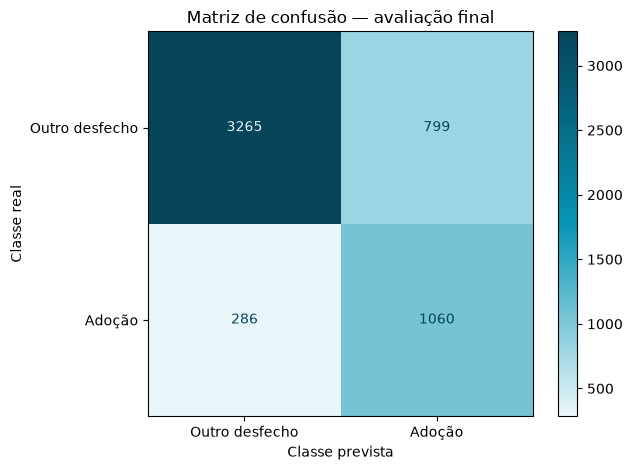

In [105]:

from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay


pasta_graficos = Path("../resultados/graficos")
pasta_graficos.mkdir(parents=True, exist_ok=True)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_teste,
    display_labels=["Outro desfecho", "Adoção"]
)

azul_miau = LinearSegmentedColormap.from_list(
    "azul_miau",
    ["#EAF7FA", "#0795B5", "#06445A"]
)

disp.plot(
    values_format="d",
    cmap=azul_miau,
    colorbar=True
)

plt.title("Matriz de confusão — avaliação final")
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.tight_layout()

plt.savefig(
    pasta_graficos / "matriz_confusao_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [86]:
configuracao_modelo = {
    "modelo": "Regressão Logística",
    "class_weight": "balanced",
    "max_iter": 1000,
    "random_state": 42,
    "proporcao_treino": 0.60,
    "proporcao_validacao": 0.20,
    "proporcao_teste": 0.20,
    "quantidade_caracteristicas": X_class_treino_preparado.shape[1]
}

configuracao_df = pd.DataFrame(
    list(configuracao_modelo.items()),
    columns=["Parametro", "Valor"]
)

pasta_metricas = Path("../resultados/metricas")

configuracao_df.to_csv(
    pasta_metricas / "configuracao_modelo.csv",
    index=False,
    encoding="utf-8-sig"
)

configuracao_df

,Parametro,Valor
0,modelo,Regressão Logística
1,class_weight,balanced
2,max_iter,1000
3,random_state,42
4,proporcao_treino,0.6
5,proporcao_validacao,0.2
6,proporcao_teste,0.2
7,quantidade_caracteristicas,142


In [87]:
from pathlib import Path
import joblib

# Pasta onde os arquivos do modelo serão salvos
pasta_modelos = Path("../modelos")
pasta_modelos.mkdir(parents=True, exist_ok=True)

# Salvar o pré-processador e o modelo treinados
joblib.dump(
    preprocessador_class,
    pasta_modelos / "preprocessador_class.joblib"
)

joblib.dump(
    modelo_logistico_balanceado,
    pasta_modelos / "modelo_logistico_balanceado.joblib"
)

print("Modelo e pré-processador salvos com sucesso!")

Modelo e pré-processador salvos com sucesso!


In [88]:
import joblib
import numpy as np
from pathlib import Path

pasta_modelos = Path("../modelos")

modelo_salvo = joblib.load(
    pasta_modelos / "modelo_logistico_balanceado.joblib"
)

preprocessador_salvo = joblib.load(
    pasta_modelos / "preprocessador_class.joblib"
)

# Compara os coeficientes do modelo atual e do modelo salvo
print(
    "Coeficientes iguais:",
    np.allclose(
        modelo_logistico_balanceado.coef_,
        modelo_salvo.coef_
    )
)

print(
    "Interceptos iguais:",
    np.allclose(
        modelo_logistico_balanceado.intercept_,
        modelo_salvo.intercept_
    )
)

# Confere a quantidade de características utilizadas
print(
    "Características do modelo atual:",
    modelo_logistico_balanceado.n_features_in_
)

print(
    "Características do modelo salvo:",
    modelo_salvo.n_features_in_
)

print(
    "Quantidade de características do pré-processador:",
    len(preprocessador_salvo.get_feature_names_out())
)

Coeficientes iguais: True
Interceptos iguais: True
Características do modelo atual: 142
Características do modelo salvo: 142
Quantidade de características do pré-processador: 142


In [89]:
# Usa o primeiro registro do conjunto de teste
exemplo = X_class_teste.iloc[[0]]

# Previsão usando os objetos que estão na memória do notebook
exemplo_preparado = preprocessador_class.transform(exemplo)

previsao_notebook = modelo_logistico_balanceado.predict(
    exemplo_preparado
)[0]

pontuacao_notebook = modelo_logistico_balanceado.predict_proba(
    exemplo_preparado
)[0, 1]

print("Características do exemplo:")
display(exemplo)

print("Classe prevista:", previsao_notebook)
print("Pontuação de adoção:", round(pontuacao_notebook, 4))

Características do exemplo:


,idade_na_entrada,Sex,Intake Condition,Intake Type,Intake Subtype,Primary Color,Jurisdiction
32744,0.057495,Male,UNDER AGE/WEIGHT,STRAY,OTC,BRN TABBY,LONG BEACH


Classe prevista: 0
Pontuação de adoção: 0.2256


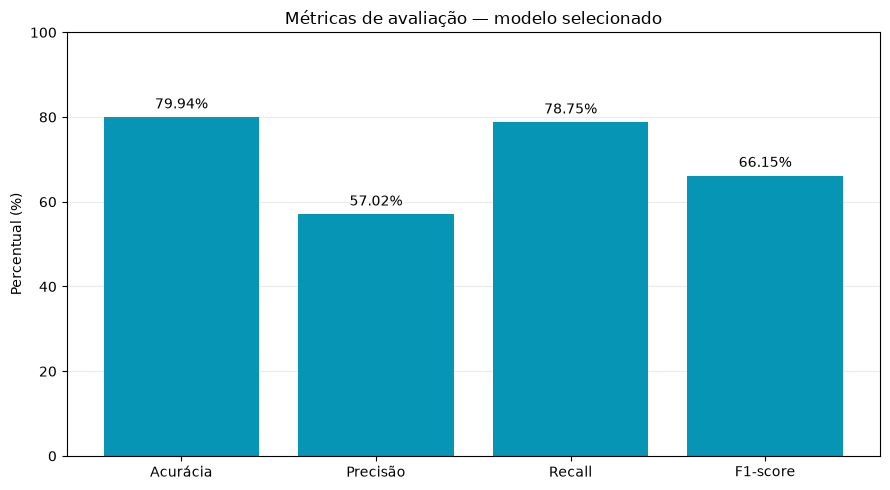

In [90]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Localiza a pasta principal do projeto
raiz = Path.cwd().parent
arquivo_csv = raiz / "resultados" / "metricas" / "metricas_finais.csv"

# Lê os resultados já calculados
df = pd.read_csv(arquivo_csv)

colunas = ["Acurácia", "Precisão", "Recall", "F1-score"]
valores = df.loc[0, colunas].astype(float) * 100

# Cria o gráfico
fig, ax = plt.subplots(figsize=(9, 5))

barras = ax.bar(
    colunas,
    valores,
    color="#0795B5"
    )

ax.set_title("Métricas de avaliação — modelo selecionado")
ax.set_ylabel("Percentual (%)")
ax.set_ylim(0, 100)
ax.bar_label(barras, fmt="%.2f%%", padding=4)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

# Salva a imagem sem alterar os arquivos existentes
pasta_graficos = raiz / "resultados" / "graficos"
pasta_graficos.mkdir(parents=True, exist_ok=True)

plt.savefig(
    pasta_graficos / "metricas_avaliacao_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
